In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
import numpy as np
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import (train_test_split, StratifiedShuffleSplit, KFold, LeaveOneOut, StratifiedKFold)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.feature_selection import SelectKBest, f_classif
from collections import Counter

In [8]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

df["especie"] = df["target"].map(dict(enumerate(iris.target_names)))

print("Forma (filas, columnas):", df.shape)
df.info()

print(df.describe().round(2))

Forma (filas, columnas): (150, 6)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   especie            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.0

Matriz de corr
                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)               1.00             -0.12               0.87   
sepal width (cm)               -0.12              1.00              -0.43   
petal length (cm)               0.87             -0.43               1.00   
petal width (cm)                0.82             -0.37               0.96   

                   petal width (cm)  
sepal length (cm)              0.82  
sepal width (cm)              -0.37  
petal length (cm)              0.96  
petal width (cm)               1.00  


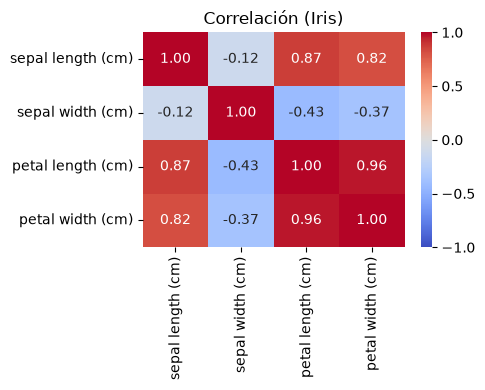


VIF
            variable    VIF
0  sepal length (cm)   7.07
1   sepal width (cm)   2.10
2  petal length (cm)  31.26
3   petal width (cm)  16.09


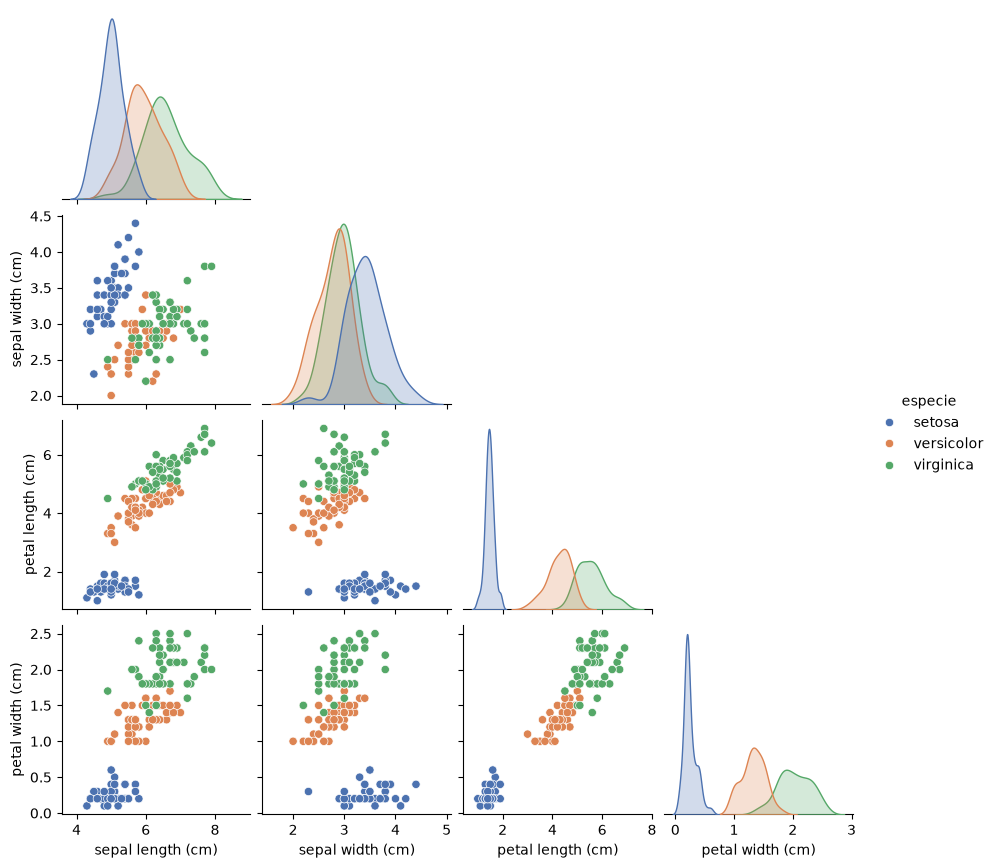

In [9]:
features = iris.feature_names

corr = df[features].corr()
print("Matriz de corr")
print(corr.round(2))

fig, ax = plt.subplots(figsize=(5, 4), facecolor="white")
ax.set_facecolor("white")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación (Iris)")
plt.tight_layout()
plt.show()

X = df[features].copy()
X_const = X.copy()
X_const.insert(0, "const", 1.0)
vif = pd.DataFrame({
    "variable": features,
    "VIF": [variance_inflation_factor(X_const.values, i + 1) for i in range(len(features))]
})
print("\nVIF")
print(vif.round(2))

g = sns.pairplot(df, vars=features, hue="especie", corner=True, height=2.2,
                 palette=["#4c72b0", "#dd8452", "#55a868"])
g.figure.set_facecolor("white")
for a in g.axes.flatten():
    if a is not None:
        a.set_facecolor("white")
plt.show()

In [10]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["especie"] = df["target"].map(dict(enumerate(iris.target_names)))

features = iris.feature_names
X = df[features]
y = df["target"]

print("X:", X.shape, "| y:", y.shape)
print("Clases:", y.value_counts().sort_index().tolist())

X: (150, 4) | y: (150,)
Clases: [50, 50, 50]


In [11]:
# Semilla
SEMILLA = int(np.random.SeedSequence().entropy % (2**31))
print("Semilla de esta corrida:", SEMILLA,)
rng = np.random.RandomState(SEMILLA)
sub = lambda: int(rng.randint(0, 2**31 - 1))  

pos = np.arange(len(X))
particiones = {}

#Hold-Out 60/40 
tr, te = train_test_split(pos, test_size=0.40, stratify=y, random_state=sub())
particiones["Hold-Out 60/40"] = [(tr, te)]

#Entrenamiento/Prueba 100/100
particiones["Train/Test 100/100"] = [(pos, pos)]

#Random subsampling N=30 
sss = StratifiedShuffleSplit(n_splits=30, test_size=0.40, random_state=sub())
particiones["Random subsampling N=30"] = list(sss.split(X, y))

#K-fold K=10 
particiones["K-fold K=10"] = list(KFold(10, shuffle=True, random_state=sub()).split(X))

#Leave-one-out
particiones["Leave-one-out"] = list(LeaveOneOut().split(X))

# 6) Stratified cross-validation K=10
particiones["Stratified K=10"] = list(StratifiedKFold(10, shuffle=True, random_state=sub()).split(X, y))

# Verificaciones
filas = []
for nombre, parts in particiones.items():
    sin_traslape = all(len(set(a) & set(b)) == 0 for a, b in parts) if nombre != "Train/Test 100/100" else "n/a (a propósito)"
    todas_te = np.concatenate([b for _, b in parts])
    cubre_1_vez = (len(todas_te) == len(X) and len(set(todas_te)) == len(X))
    filas.append({
        "método": nombre,
        "n particiones": len(parts),
        "train (min-max)": f"{min(len(a) for a,_ in parts)}-{max(len(a) for a,_ in parts)}",
        "test (min-max)":  f"{min(len(b) for _,b in parts)}-{max(len(b) for _,b in parts)}",
        "sin traslape": sin_traslape,
        "cada fila 1 vez en test": cubre_1_vez,
    })
print(pd.DataFrame(filas).set_index("método").to_string())


Semilla de esta corrida: 809719128
                         n particiones train (min-max) test (min-max)       sin traslape  cada fila 1 vez en test
método                                                                                                           
Hold-Out 60/40                       1           90-90          60-60               True                    False
Train/Test 100/100                   1         150-150        150-150  n/a (a propósito)                     True
Random subsampling N=30             30           90-90          60-60               True                    False
K-fold K=10                         10         135-135          15-15               True                     True
Leave-one-out                      150         149-149            1-1               True                     True
Stratified K=10                     10         135-135          15-15               True                     True


In [12]:
semilla_modelos = sub()
print("Semilla de los modelos:", semilla_modelos)

y_arr = y.values
cols_metricas = ["exactitud", "tasa_error", "precision", "recall", "especificidad",
                 "F1", "F2", "exactitud_balanceada", "MCC", "kappa"]
resultados = {}     
predicciones = {}    

def metricas(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=[0, 1, 2])
    espec = []
    for k in range(3):
        tn = cm.sum() - cm[k, :].sum() - cm[:, k].sum() + cm[k, k]
        fp = cm[:, k].sum() - cm[k, k]
        espec.append(tn / (tn + fp))
    acc = accuracy_score(y_real, y_pred)
    return {
        "exactitud": acc,
        "tasa_error": 1 - acc,
        "precision": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "especificidad": float(np.mean(espec)),
        "F1": f1_score(y_real, y_pred, average="macro", zero_division=0),
        "F2": fbeta_score(y_real, y_pred, beta=2, average="macro", zero_division=0),
        "exactitud_balanceada": balanced_accuracy_score(y_real, y_pred),
        "MCC": matthews_corrcoef(y_real, y_pred),
        "kappa": cohen_kappa_score(y_real, y_pred),
    }

def evaluar(nombre, fabrica):
    filas = []
    for metodo, parts in particiones.items():
        lista, reales, preds = [], [], []
        for tr, te in parts:
            modelo = fabrica()                     
            modelo.fit(X.iloc[tr], y_arr[tr])
            p = modelo.predict(X.iloc[te])
            reales.append(y_arr[te]); preds.append(p)
            if metodo != "Leave-one-out":
                lista.append(metricas(y_arr[te], p))
        reales, preds = np.concatenate(reales), np.concatenate(preds)
        predicciones[(metodo, nombre)] = (reales, preds)

        fila = {"método": metodo, "modelo": nombre}
        if metodo == "Leave-one-out":               
            for k, v in metricas(reales, preds).items():
                fila[k] = v; fila[k + "_std"] = np.nan
        else:
            dfm = pd.DataFrame(lista)
            for k in dfm.columns:
                fila[k] = dfm[k].mean()
                fila[k + "_std"] = dfm[k].std(ddof=1) if len(dfm) > 1 else np.nan
        filas.append(fila)
    return pd.DataFrame(filas)

def mostrar(nombre):
    tabla = resultados[nombre]
    print(f"{nombre}")
    print(tabla[["método"] + cols_metricas].round(4).to_string(index=False))
    print("\nDesviación estándar entre particiones (exactitud y F1):")
    print(tabla[["método", "exactitud_std", "F1_std"]].round(4).to_string(index=False))

    fig, axes = plt.subplots(2, 3, figsize=(11, 7), facecolor="white")
    for ax, metodo in zip(axes.ravel(), particiones.keys()):
        ax.set_facecolor("white")
        real, pred = predicciones[(metodo, nombre)]
        cm = confusion_matrix(real, pred, labels=[0, 1, 2])
        ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{metodo}\n({len(real)} predicciones)", fontsize=10)
        ax.tick_params(axis="x", rotation=30)
    fig.suptitle(f"Matrices de confusión: {nombre} (sin Feature Selection)")
    plt.tight_layout()
    plt.show()

Semilla de los modelos: 72651631


Regresión Logística
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9500      0.0500     0.9507  0.9500         0.9750 0.9500 0.9499                0.9500 0.9254 0.9250
     Train/Test 100/100     0.9733      0.0267     0.9738  0.9733         0.9867 0.9733 0.9733                0.9733 0.9603 0.9600
Random subsampling N=30     0.9517      0.0483     0.9544  0.9517         0.9758 0.9516 0.9513                0.9517 0.9290 0.9275
            K-fold K=10     0.9533      0.0467     0.9276  0.9305         0.9761 0.9225 0.9257                0.9305 0.9327 0.9260
          Leave-one-out     0.9533      0.0467     0.9534  0.9533         0.9767 0.9533 0.9533                0.9533 0.9301 0.9300
        Stratified K=10     0.9533      0.0467     0.9589  0.9533         0.9767 0.9530 0.9525                0.9533 0.9330 0.9300

Desviación estándar entre particiones (exactitud y F1):
      

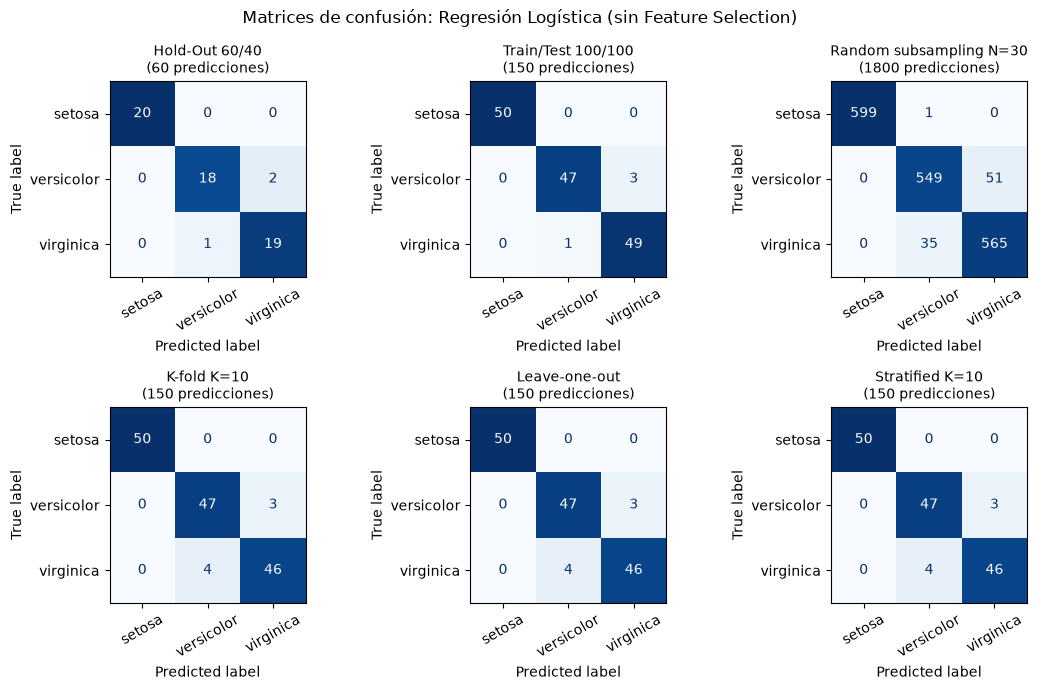

In [13]:
nombre = "Regresión Logística"
resultados[nombre] = evaluar(nombre, lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
mostrar(nombre)

Red Neuronal
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9500      0.0500     0.9507  0.9500         0.9750 0.9500 0.9499                0.9500 0.9254 0.9250
     Train/Test 100/100     0.9733      0.0267     0.9738  0.9733         0.9867 0.9733 0.9733                0.9733 0.9603 0.9600
Random subsampling N=30     0.9511      0.0489     0.9546  0.9511         0.9756 0.9510 0.9506                0.9511 0.9285 0.9267
            K-fold K=10     0.9533      0.0467     0.9276  0.9305         0.9761 0.9225 0.9257                0.9305 0.9327 0.9260
          Leave-one-out     0.9600      0.0400     0.9600  0.9600         0.9800 0.9600 0.9600                0.9600 0.9400 0.9400
        Stratified K=10     0.9667      0.0333     0.9694  0.9667         0.9833 0.9663 0.9661                0.9667 0.9517 0.9500

Desviación estándar entre particiones (exactitud y F1):
             

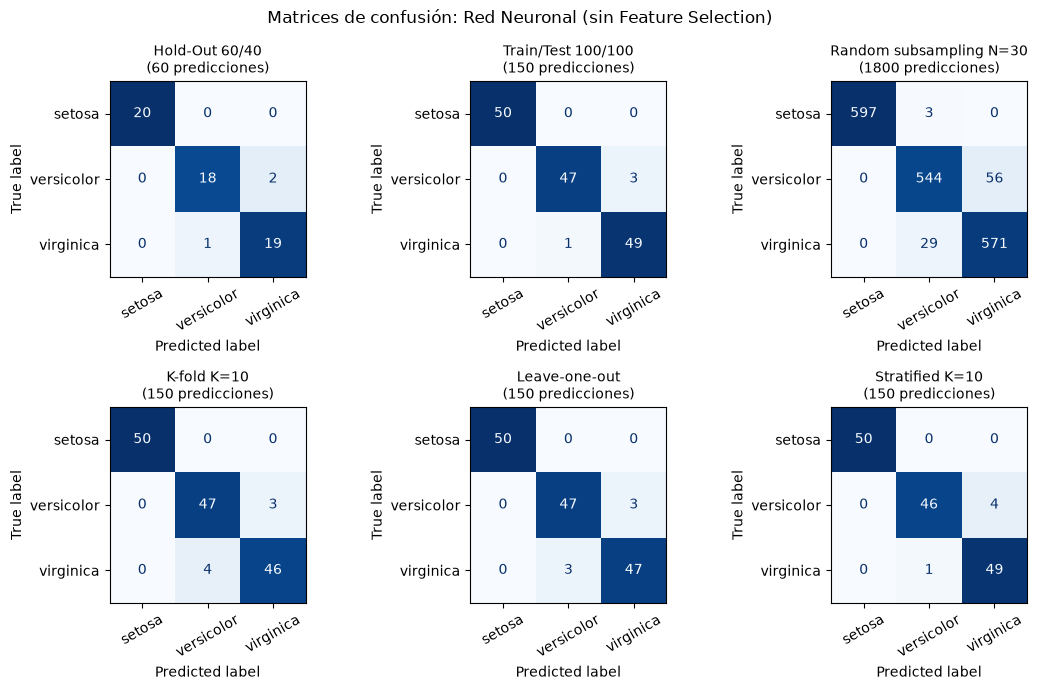

In [14]:
nombre = "Red Neuronal"
resultados[nombre] = evaluar(nombre, lambda: make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=semilla_modelos)))
mostrar(nombre)

Árbol de Decisión
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9667      0.0333     0.9697  0.9667         0.9833 0.9666 0.9663                0.9667 0.9516 0.9500
     Train/Test 100/100     1.0000      0.0000     1.0000  1.0000         1.0000 1.0000 1.0000                1.0000 1.0000 1.0000
Random subsampling N=30     0.9367      0.0633     0.9432  0.9367         0.9683 0.9362 0.9356                0.9367 0.9086 0.9050
            K-fold K=10     0.9400      0.0600     0.9181  0.9210         0.9694 0.9114 0.9151                0.9210 0.9144 0.9055
          Leave-one-out     0.9467      0.0533     0.9471  0.9467         0.9733 0.9466 0.9466                0.9467 0.9202 0.9200
        Stratified K=10     0.9400      0.0600     0.9450  0.9400         0.9700 0.9395 0.9391                0.9400 0.9129 0.9100

Desviación estándar entre particiones (exactitud y F1):
        

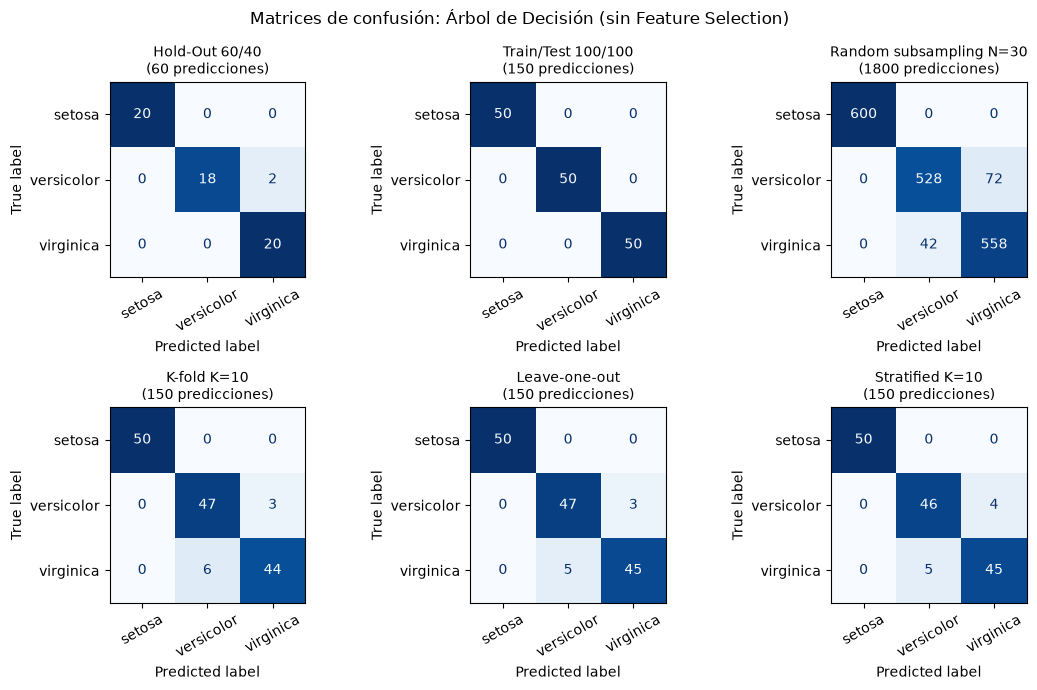

In [15]:
nombre = "Árbol de Decisión"
resultados[nombre] = evaluar(nombre, lambda: make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=semilla_modelos)))
mostrar(nombre)

SVM
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9667      0.0333     0.9697  0.9667         0.9833 0.9666 0.9663                0.9667 0.9516 0.9500
     Train/Test 100/100     0.9733      0.0267     0.9733  0.9733         0.9867 0.9733 0.9733                0.9733 0.9600 0.9600
Random subsampling N=30     0.9556      0.0444     0.9581  0.9556         0.9778 0.9554 0.9552                0.9556 0.9347 0.9333
            K-fold K=10     0.9533      0.0467     0.9276  0.9305         0.9761 0.9225 0.9257                0.9305 0.9327 0.9260
          Leave-one-out     0.9667      0.0333     0.9668  0.9667         0.9833 0.9667 0.9667                0.9667 0.9501 0.9500
        Stratified K=10     0.9733      0.0267     0.9778  0.9733         0.9867 0.9731 0.9726                0.9733 0.9624 0.9600

Desviación estándar entre particiones (exactitud y F1):
                 métod

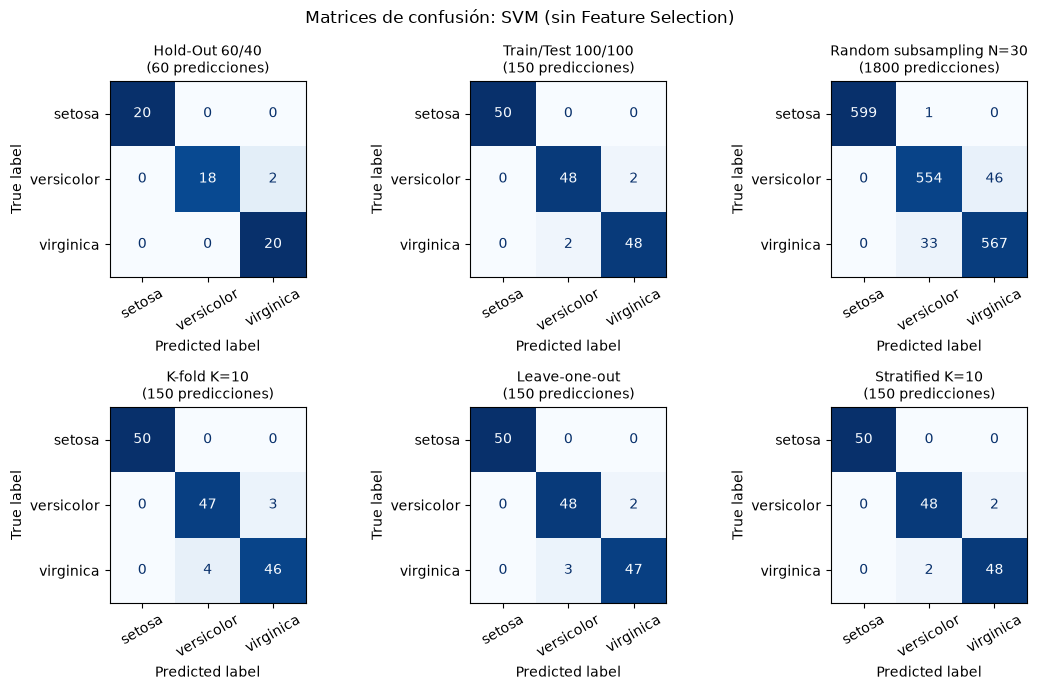

In [16]:
nombre = "SVM"
resultados[nombre] = evaluar(nombre, lambda: make_pipeline(StandardScaler(), SVC(random_state=semilla_modelos)))
mostrar(nombre)

Naive Bayes
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9667      0.0333     0.9697  0.9667         0.9833 0.9666 0.9663                0.9667 0.9516  0.950
     Train/Test 100/100     0.9600      0.0400     0.9600  0.9600         0.9800 0.9600 0.9600                0.9600 0.9400  0.940
Random subsampling N=30     0.9500      0.0500     0.9530  0.9500         0.9750 0.9498 0.9495                0.9500 0.9266  0.925
            K-fold K=10     0.9467      0.0533     0.9221  0.9249         0.9727 0.9165 0.9198                0.9249 0.9233  0.916
          Leave-one-out     0.9533      0.0467     0.9534  0.9533         0.9767 0.9533 0.9533                0.9533 0.9301  0.930
        Stratified K=10     0.9467      0.0533     0.9571  0.9467         0.9733 0.9457 0.9449                0.9467 0.9259  0.920

Desviación estándar entre particiones (exactitud y F1):
              

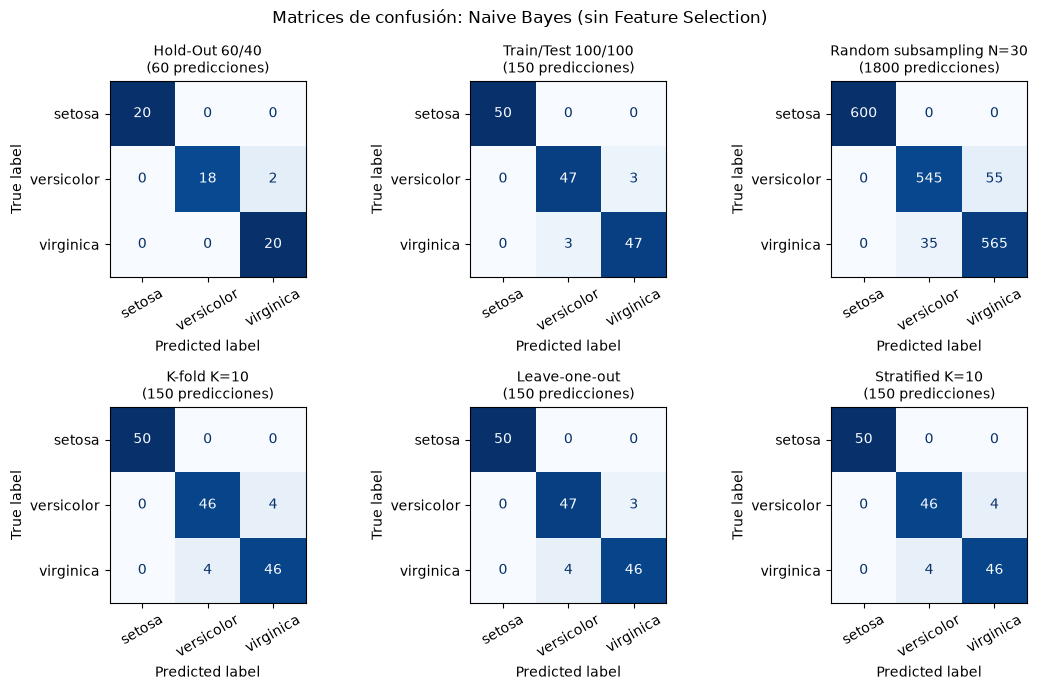

In [17]:
nombre = "Naive Bayes"
resultados[nombre] = evaluar(nombre, lambda: make_pipeline(StandardScaler(), GaussianNB()))
mostrar(nombre)

In [18]:
K = 2
predicciones_fs = {}
resultados_fs = {}
selecciones_fs = {} 

def evaluar_fs(nombre, clasificador_fabrica, k=K):
    filas = []
    selecciones_fs[nombre] = {}
    for metodo, parts in particiones.items():
        lista, reales, preds = [], [], []
        conteo = Counter()
        for tr, te in parts:
            modelo = make_pipeline(StandardScaler(),
                                   SelectKBest(f_classif, k=k),
                                   clasificador_fabrica())
            modelo.fit(X.iloc[tr], y_arr[tr])          
            elegidas = tuple(np.array(features)[modelo[1].get_support()])
            conteo[elegidas] += 1
            p = modelo.predict(X.iloc[te])
            reales.append(y_arr[te]); preds.append(p)
            if metodo != "Leave-one-out":
                lista.append(metricas(y_arr[te], p))
        reales, preds = np.concatenate(reales), np.concatenate(preds)
        predicciones_fs[(metodo, nombre)] = (reales, preds)
        selecciones_fs[nombre][metodo] = conteo

        fila = {"método": metodo, "modelo": nombre}
        if metodo == "Leave-one-out":
            for kk, v in metricas(reales, preds).items():
                fila[kk] = v; fila[kk + "_std"] = np.nan
        else:
            dfm = pd.DataFrame(lista)
            for kk in dfm.columns:
                fila[kk] = dfm[kk].mean()
                fila[kk + "_std"] = dfm[kk].std(ddof=1) if len(dfm) > 1 else np.nan
        filas.append(fila)
    return pd.DataFrame(filas)

def mostrar_fs(nombre):
    t = resultados_fs[nombre]
    print(f"{nombre} CON Feature Selection (ANOVA F, k={K})")
    print(t[["método"] + cols_metricas].round(4).to_string(index=False))

    sin = resultados[nombre].set_index("método")
    con = t.set_index("método")
    comp = pd.DataFrame({
        "exactitud sin FS": sin["exactitud"],
        "exactitud con FS": con["exactitud"],
        "diferencia": con["exactitud"] - sin["exactitud"],
        "F1 sin FS": sin["F1"],
        "F1 con FS": con["F1"],
    })
    print("\nComparación con y sin FS")
    print(comp.round(4).to_string())

    print("\nVariables elegidas por ANOVA")
    for metodo, conteo in selecciones_fs[nombre].items():
        print(f"{metodo}:")
        for combo, n in conteo.most_common():
            print(f"    {n:>3} x {list(combo)}")

    fig, axes = plt.subplots(2, 3, figsize=(11, 7), facecolor="white")
    for ax, metodo in zip(axes.ravel(), particiones.keys()):
        ax.set_facecolor("white")
        real, pred = predicciones_fs[(metodo, nombre)]
        cm = confusion_matrix(real, pred, labels=[0, 1, 2])
        ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(ax=ax, colorbar=False, cmap="Greens")
        ax.set_title(f"{metodo}\n({len(real)} predicciones)", fontsize=10)
        ax.tick_params(axis="x", rotation=30)
    fig.suptitle(f"Matrices de confusión: {nombre} (con Feature Selection, ANOVA k={K})")
    plt.tight_layout()
    plt.show()

Regresión Logística CON Feature Selection (ANOVA F, k=2)
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9500      0.0500     0.9507  0.9500         0.9750 0.9500 0.9499                0.9500 0.9254 0.9250
     Train/Test 100/100     0.9533      0.0467     0.9534  0.9533         0.9767 0.9533 0.9533                0.9533 0.9301 0.9300
Random subsampling N=30     0.9550      0.0450     0.9567  0.9550         0.9775 0.9549 0.9548                0.9550 0.9334 0.9325
            K-fold K=10     0.9533      0.0467     0.9276  0.9305         0.9761 0.9225 0.9257                0.9305 0.9327 0.9260
          Leave-one-out     0.9533      0.0467     0.9534  0.9533         0.9767 0.9533 0.9533                0.9533 0.9301 0.9300
        Stratified K=10     0.9533      0.0467     0.9589  0.9533         0.9767 0.9530 0.9525                0.9533 0.9330 0.9300

Comparación con y sin FS


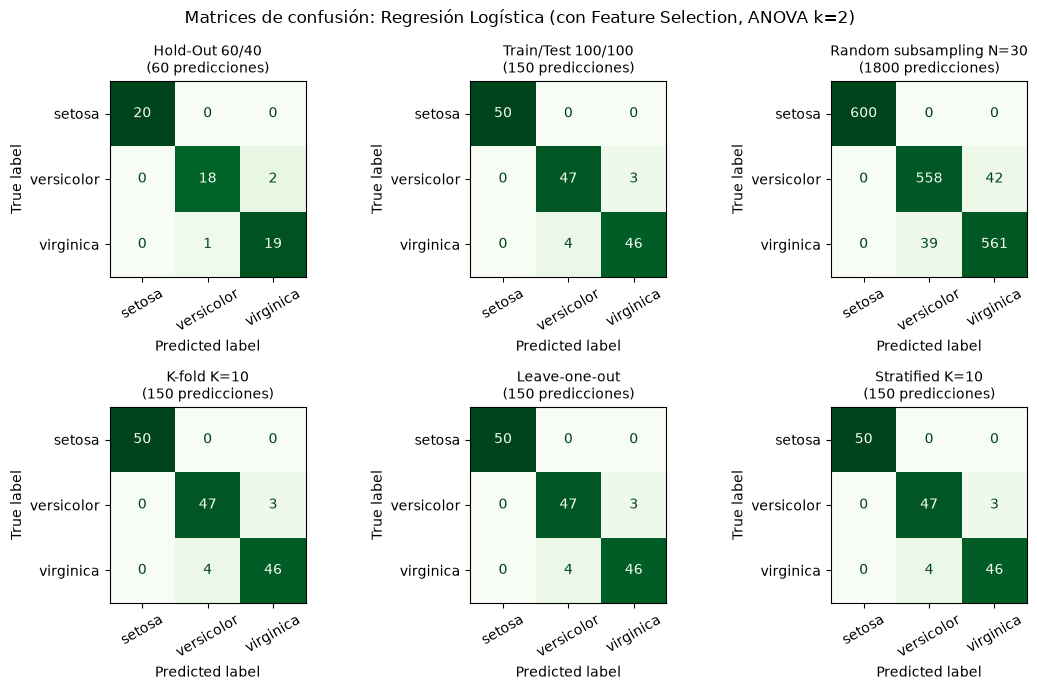

In [19]:
nombre = "Regresión Logística"
resultados_fs[nombre] = evaluar_fs(nombre, lambda: LogisticRegression(max_iter=1000))
mostrar_fs(nombre)

Red Neuronal CON Feature Selection (ANOVA F, k=2)
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9500      0.0500     0.9507  0.9500         0.9750 0.9500 0.9499                0.9500 0.9254 0.9250
     Train/Test 100/100     0.9600      0.0400     0.9600  0.9600         0.9800 0.9600 0.9600                0.9600 0.9400 0.9400
Random subsampling N=30     0.9550      0.0450     0.9571  0.9550         0.9775 0.9549 0.9547                0.9550 0.9336 0.9325
            K-fold K=10     0.9533      0.0467     0.9276  0.9305         0.9761 0.9225 0.9257                0.9305 0.9327 0.9260
          Leave-one-out     0.9533      0.0467     0.9534  0.9533         0.9767 0.9533 0.9533                0.9533 0.9301 0.9300
        Stratified K=10     0.9533      0.0467     0.9589  0.9533         0.9767 0.9530 0.9525                0.9533 0.9330 0.9300

Comparación con y sin FS
       

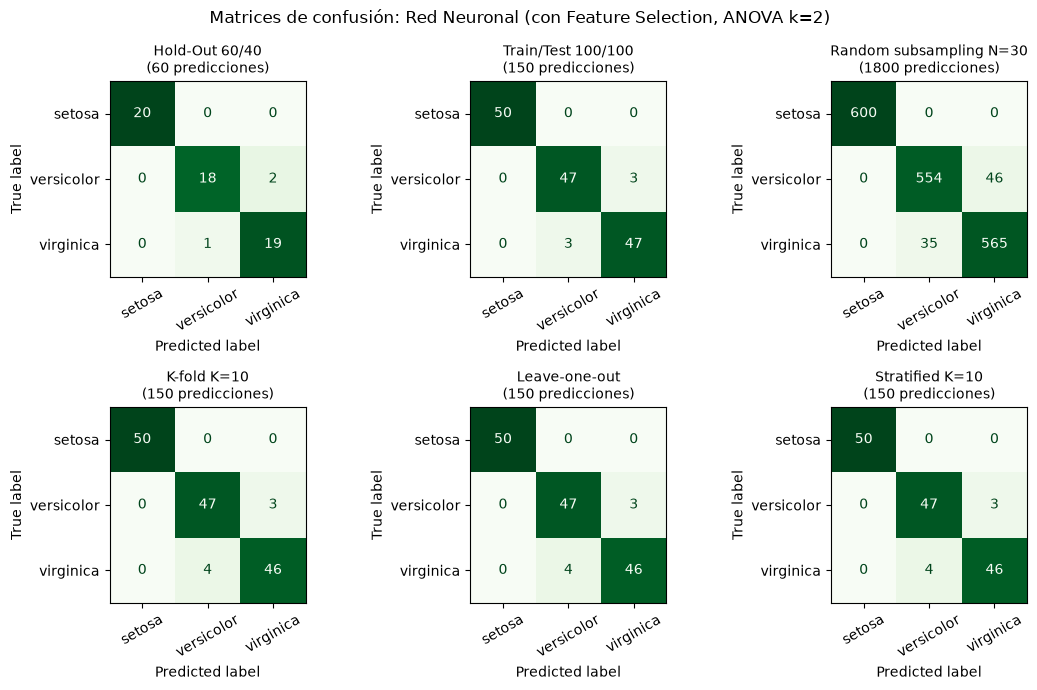

In [20]:
nombre = "Red Neuronal"
resultados_fs[nombre] = evaluar_fs(nombre, lambda: MLPClassifier(max_iter=1000, random_state=semilla_modelos))
mostrar_fs(nombre)

Árbol de Decisión CON Feature Selection (ANOVA F, k=2)
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9667      0.0333     0.9697  0.9667         0.9833 0.9666 0.9663                0.9667 0.9516 0.9500
     Train/Test 100/100     0.9933      0.0067     0.9935  0.9933         0.9967 0.9933 0.9933                0.9933 0.9901 0.9900
Random subsampling N=30     0.9439      0.0561     0.9495  0.9439         0.9719 0.9435 0.9430                0.9439 0.9189 0.9158
            K-fold K=10     0.9467      0.0533     0.9551  0.9543         0.9742 0.9467 0.9493                0.9543 0.9263 0.9183
          Leave-one-out     0.9467      0.0533     0.9471  0.9467         0.9733 0.9466 0.9466                0.9467 0.9202 0.9200
        Stratified K=10     0.9467      0.0533     0.9549  0.9467         0.9733 0.9458 0.9453                0.9467 0.9246 0.9200

Comparación con y sin FS
  

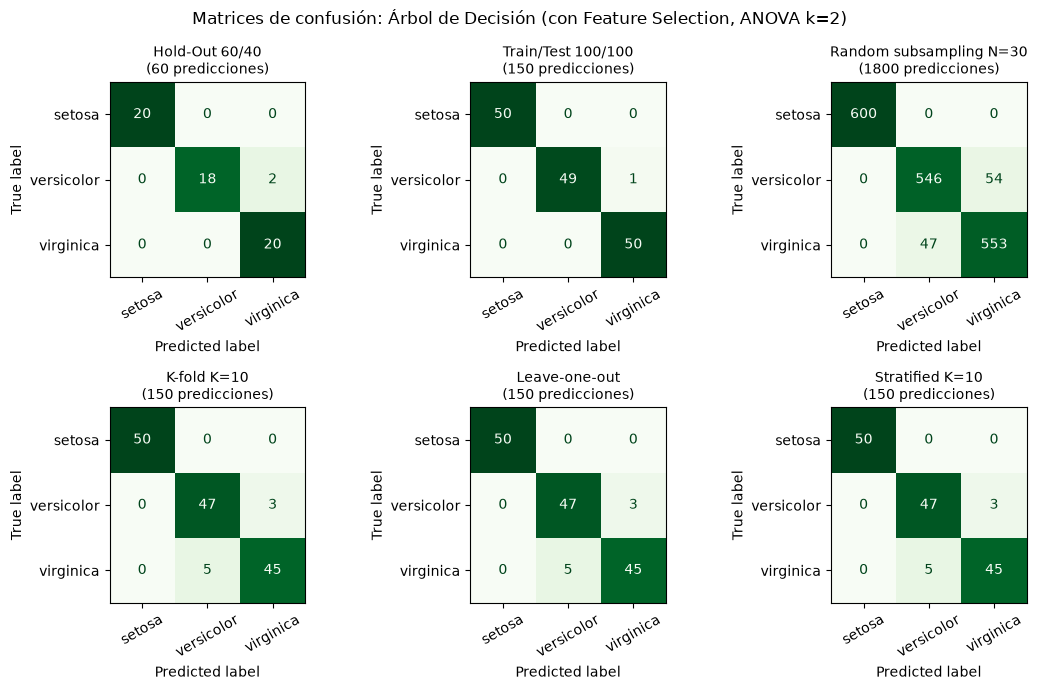

In [21]:
nombre = "Árbol de Decisión"
resultados_fs[nombre] = evaluar_fs(nombre, lambda: DecisionTreeClassifier(random_state=semilla_modelos))
mostrar_fs(nombre)

Naive Bayes CON Feature Selection (ANOVA F, k=2)
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9667      0.0333     0.9697  0.9667         0.9833 0.9666 0.9663                0.9667 0.9516 0.9500
     Train/Test 100/100     0.9600      0.0400     0.9600  0.9600         0.9800 0.9600 0.9600                0.9600 0.9400 0.9400
Random subsampling N=30     0.9572      0.0428     0.9591  0.9572         0.9786 0.9572 0.9570                0.9572 0.9368 0.9358
            K-fold K=10     0.9600      0.0400     0.9326  0.9352         0.9788 0.9291 0.9317                0.9352 0.9409 0.9358
          Leave-one-out     0.9600      0.0400     0.9600  0.9600         0.9800 0.9600 0.9600                0.9600 0.9400 0.9400
        Stratified K=10     0.9600      0.0400     0.9644  0.9600         0.9800 0.9597 0.9593                0.9600 0.9424 0.9400

Comparación con y sin FS
        

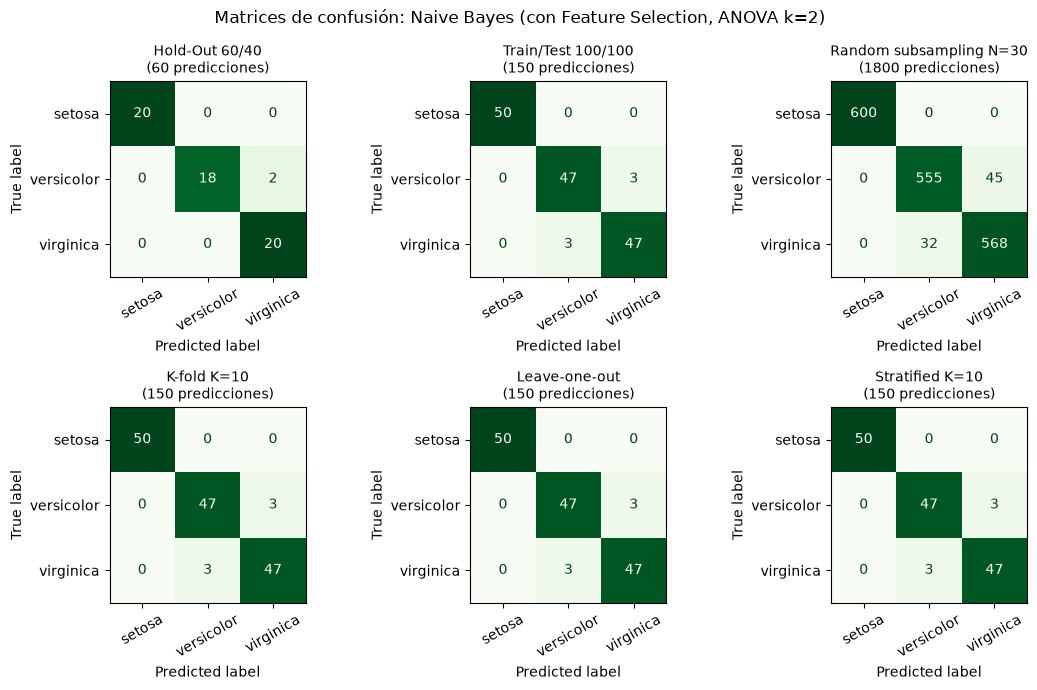

In [22]:
nombre = "Naive Bayes"
resultados_fs[nombre] = evaluar_fs(nombre, lambda: GaussianNB())
mostrar_fs(nombre)

SVM CON Feature Selection (ANOVA F, k=2)
                 método  exactitud  tasa_error  precision  recall  especificidad     F1     F2  exactitud_balanceada    MCC  kappa
         Hold-Out 60/40     0.9667      0.0333     0.9667  0.9667         0.9833 0.9667 0.9667                0.9667 0.9500 0.9500
     Train/Test 100/100     0.9600      0.0400     0.9600  0.9600         0.9800 0.9600 0.9600                0.9600 0.9400 0.9400
Random subsampling N=30     0.9561      0.0439     0.9577  0.9561         0.9781 0.9560 0.9559                0.9561 0.9350 0.9342
            K-fold K=10     0.9533      0.0467     0.9276  0.9305         0.9761 0.9225 0.9257                0.9305 0.9327 0.9260
          Leave-one-out     0.9533      0.0467     0.9534  0.9533         0.9767 0.9533 0.9533                0.9533 0.9301 0.9300
        Stratified K=10     0.9600      0.0400     0.9667  0.9600         0.9800 0.9596 0.9590                0.9600 0.9436 0.9400

Comparación con y sin FS
                

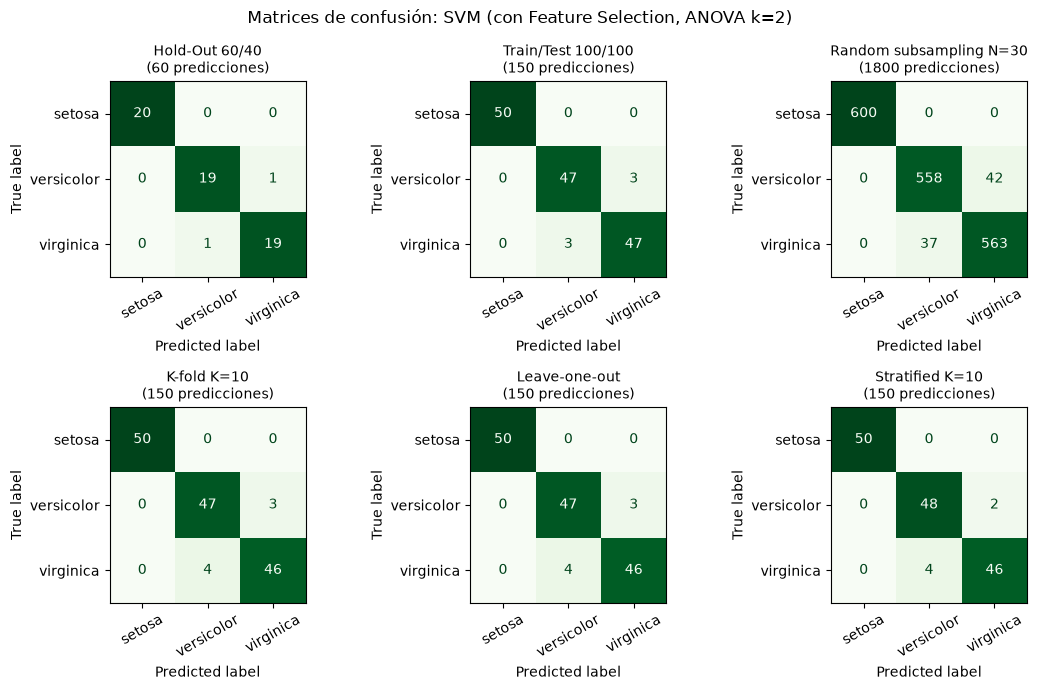

In [23]:
nombre = "SVM"
resultados_fs[nombre] = evaluar_fs(nombre, lambda: SVC(random_state=semilla_modelos))
mostrar_fs(nombre)

In [24]:
resumen_fs = pd.concat(resultados_fs.values(), ignore_index=True)
print(resumen_fs.shape)   # esperado: (30, ...)

(30, 22)


In [25]:
resumen_sin_fs = pd.concat(resultados.values(), ignore_index=True)
print(resumen_sin_fs.shape)   # esperado: (30, ...) = 5 modelos x 6 métodos

(30, 22)


                modelo   feature_selection  F1_medio  exactitud_media  F1_std_medio  dif_vs_mejor  empate_tecnico
0                  SVM              Sin FS    0.9544           0.9622        0.0555        0.0000            True
1          Naive Bayes  Con FS (ANOVA k=2)    0.9515           0.9593        0.0589       -0.0029            True
2         Red Neuronal              Sin FS    0.9500           0.9578        0.0665       -0.0045            True
3                  SVM  Con FS (ANOVA k=2)    0.9479           0.9557        0.0563       -0.0065            True
4  Regresión Logística  Con FS (ANOVA k=2)    0.9459           0.9538        0.0588       -0.0085           False
5         Red Neuronal  Con FS (ANOVA k=2)    0.9459           0.9538        0.0589       -0.0085           False
6    Árbol de Decisión  Con FS (ANOVA k=2)    0.9457           0.9460        0.0473       -0.0087           False
7  Regresión Logística              Sin FS    0.9451           0.9529        0.0585     

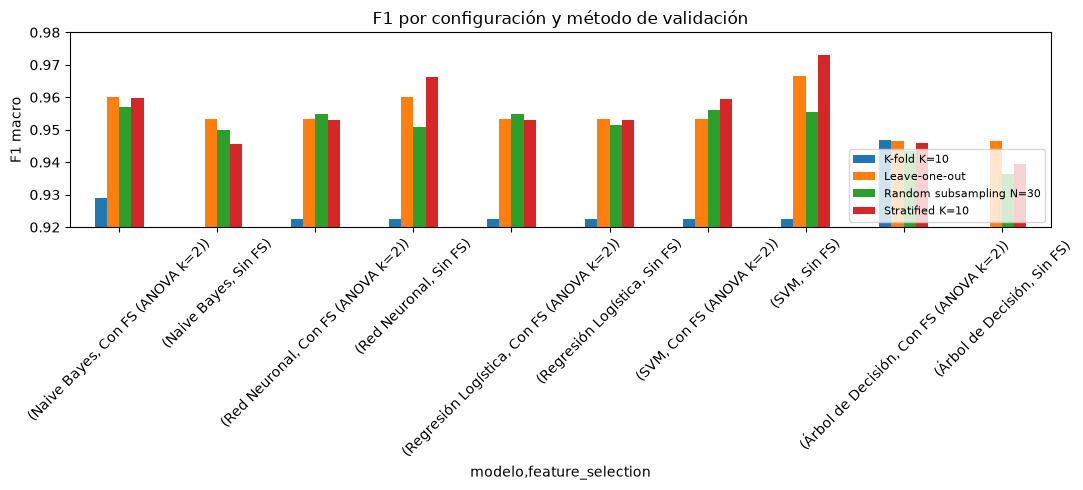

In [26]:
metodos_cv = ["Random subsampling N=30", "K-fold K=10", "Leave-one-out", "Stratified K=10"]

a = resumen_sin_fs.assign(feature_selection="Sin FS")
b = resumen_fs.assign(feature_selection="Con FS (ANOVA k=2)")
todo = pd.concat([a, b], ignore_index=True)

cv = todo[todo["método"].isin(metodos_cv)]

ranking = (cv.groupby(["modelo", "feature_selection"])
             .agg(F1_medio=("F1", "mean"),
                  exactitud_media=("exactitud", "mean"),
                  F1_std_medio=("F1_std", "mean"))   # LOO no tiene std, se ignora
             .reset_index()
             .sort_values("F1_medio", ascending=False)
             .reset_index(drop=True))
ranking["dif_vs_mejor"] = ranking["F1_medio"] - ranking["F1_medio"].iloc[0]
ranking["empate_tecnico"] = ranking["dif_vs_mejor"].abs() < 0.0067

print(ranking.round(4).to_string())

# Gráfica: F1 por configuración y método (fondo blanco)
pivote = cv.pivot_table(index=["modelo", "feature_selection"], columns="método", values="F1")
fig, ax = plt.subplots(figsize=(11, 5), facecolor="white")
ax.set_facecolor("white")
pivote.plot(kind="bar", ax=ax)
ax.set_ylim(0.92, 0.98)
ax.set_ylabel("F1 macro")
ax.set_title("F1 por configuración y método de validación")
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

X2: (149, 4) | Clases: [50, 50, 49]
¿Fila 142 presente?: False | ¿Fila 101 presente?: True
Semilla maestra (la misma): 809719128
{'Hold-Out 60/40': 1, 'Train/Test 100/100': 1, 'Random subsampling N=30': 30, 'K-fold K=10': 10, 'Leave-one-out': 149, 'Stratified K=10': 10}
listo: Regresión Logística | sin FS
listo: Regresión Logística | con FS
listo: Red Neuronal | sin FS
listo: Red Neuronal | con FS
listo: Árbol de Decisión | sin FS
listo: Árbol de Decisión | con FS
listo: Naive Bayes | sin FS
listo: Naive Bayes | con FS
listo: SVM | sin FS
listo: SVM | con FS
Forma: (60, 23)

=== Ranking SIN la fila 142 (149 filas) ===
                modelo   feature_selection  F1_medio  exactitud_media  F1_std_medio  dif_vs_mejor  empate_tecnico
0                  SVM              Sin FS    0.9501           0.9590        0.0608        0.0000            True
1          Naive Bayes  Con FS (ANOVA k=2)    0.9498           0.9588        0.0576       -0.0003            True
2         Red Neuronal          

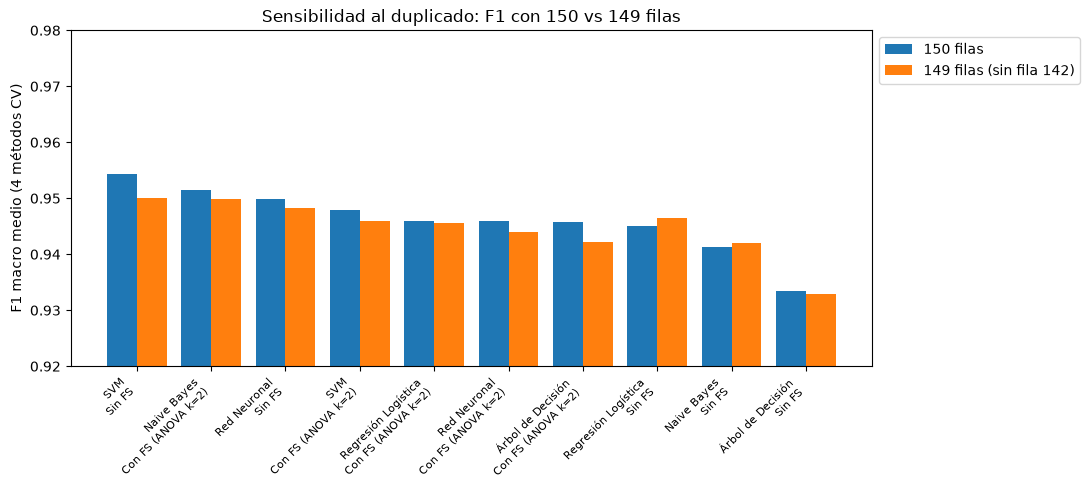

In [27]:
from sklearn.model_selection import (train_test_split, StratifiedShuffleSplit,
                                     KFold, LeaveOneOut, StratifiedKFold)
from sklearn.feature_selection import SelectKBest, f_classif

# 1) Datos sin la fila 142 (se quita por etiqueta de índice)
df2 = df.drop(index=142)
X2 = df2[features]
y2 = df2["target"]
y2_arr = y2.values
print("X2:", X2.shape, "| Clases:", y2.value_counts().sort_index().tolist())
print("¿Fila 142 presente?:", 142 in X2.index, "| ¿Fila 101 presente?:", 101 in X2.index)

# 2) Mismas sub-semillas que en la corrida original (misma semilla maestra, mismo orden de llamadas)
rng2 = np.random.RandomState(SEMILLA)
sub2 = lambda: int(rng2.randint(0, 2**31 - 1))
pos2 = np.arange(len(X2))

part2 = {}
tr, te = train_test_split(pos2, test_size=0.40, stratify=y2, random_state=sub2())
part2["Hold-Out 60/40"] = [(tr, te)]
part2["Train/Test 100/100"] = [(pos2, pos2)]
part2["Random subsampling N=30"] = list(StratifiedShuffleSplit(30, test_size=0.40, random_state=sub2()).split(X2, y2))
part2["K-fold K=10"] = list(KFold(10, shuffle=True, random_state=sub2()).split(X2))
part2["Leave-one-out"] = list(LeaveOneOut().split(X2))
part2["Stratified K=10"] = list(StratifiedKFold(10, shuffle=True, random_state=sub2()).split(X2, y2))
semilla_modelos2 = sub2()   # misma posición que semilla_modelos en la corrida original

print("Semilla maestra (la misma):", SEMILLA)
print({k: len(v) for k, v in part2.items()})

# 3) Evaluación (con o sin Feature Selection)
def evaluar2(nombre, fabrica, con_fs):
    filas = []
    for metodo, parts in part2.items():
        lista, reales, preds = [], [], []
        for tr, te in parts:
            pasos = [StandardScaler()]
            if con_fs:
                pasos.append(SelectKBest(f_classif, k=2))
            pasos.append(fabrica())
            modelo = make_pipeline(*pasos)
            modelo.fit(X2.iloc[tr], y2_arr[tr])
            p = modelo.predict(X2.iloc[te])
            reales.append(y2_arr[te]); preds.append(p)
            if metodo != "Leave-one-out":
                lista.append(metricas(y2_arr[te], p))
        reales, preds = np.concatenate(reales), np.concatenate(preds)
        fila = {"método": metodo, "modelo": nombre,
                "feature_selection": "Con FS (ANOVA k=2)" if con_fs else "Sin FS"}
        if metodo == "Leave-one-out":
            for kk, v in metricas(reales, preds).items():
                fila[kk] = v; fila[kk + "_std"] = np.nan
        else:
            dfm = pd.DataFrame(lista)
            for kk in dfm.columns:
                fila[kk] = dfm[kk].mean()
                fila[kk + "_std"] = dfm[kk].std(ddof=1) if len(dfm) > 1 else np.nan
        filas.append(fila)
    return pd.DataFrame(filas)

fabricas = {
    "Regresión Logística": lambda: LogisticRegression(max_iter=1000),
    "Red Neuronal":        lambda: MLPClassifier(max_iter=1000, random_state=semilla_modelos2),
    "Árbol de Decisión":   lambda: DecisionTreeClassifier(random_state=semilla_modelos2),
    "Naive Bayes":         lambda: GaussianNB(),
    "SVM":                 lambda: SVC(random_state=semilla_modelos2),
}

partes = []
for nombre, fab in fabricas.items():
    for con_fs in [False, True]:
        partes.append(evaluar2(nombre, fab, con_fs))
        print("listo:", nombre, "| con FS" if con_fs else "| sin FS")
todo2 = pd.concat(partes, ignore_index=True)
print("Forma:", todo2.shape)   # esperado: (60, 23)

# 4) Ranking con el mismo criterio de antes (4 métodos de validación cruzada)
metodos_cv = ["Random subsampling N=30", "K-fold K=10", "Leave-one-out", "Stratified K=10"]
cv2 = todo2[todo2["método"].isin(metodos_cv)]
ranking_149 = (cv2.groupby(["modelo", "feature_selection"])
                  .agg(F1_medio=("F1", "mean"),
                       exactitud_media=("exactitud", "mean"),
                       F1_std_medio=("F1_std", "mean"))
                  .reset_index()
                  .sort_values("F1_medio", ascending=False)
                  .reset_index(drop=True))
ranking_149["dif_vs_mejor"] = ranking_149["F1_medio"] - ranking_149["F1_medio"].iloc[0]
ranking_149["empate_tecnico"] = ranking_149["dif_vs_mejor"].abs() < 0.0067
print("\n=== Ranking SIN la fila 142 (149 filas) ===")
print(ranking_149.round(4).to_string())

# 5) Comparación con el ranking original (150 filas)
orig = ranking.copy()
orig["puesto_150"] = orig.index + 1
nuevo = ranking_149.copy()
nuevo["puesto_149"] = nuevo.index + 1
comp = orig[["modelo", "feature_selection", "F1_medio", "puesto_150"]].merge(
    nuevo[["modelo", "feature_selection", "F1_medio", "puesto_149"]],
    on=["modelo", "feature_selection"], suffixes=("_150", "_149"))
comp["cambio_F1"] = comp["F1_medio_149"] - comp["F1_medio_150"]
comp = comp.sort_values("puesto_150")
print("\n=== Comparación 150 vs 149 filas ===")
print(comp.round(4).to_string(index=False))

# 6) Gráfica de F1 medio, 150 vs 149 (fondo blanco, leyenda fuera)
etq = [f"{m}\n{fs}" for m, fs in zip(comp["modelo"], comp["feature_selection"])]
x = np.arange(len(comp)); w = 0.4
fig, ax = plt.subplots(figsize=(11, 5), facecolor="white")
ax.set_facecolor("white")
ax.bar(x - w/2, comp["F1_medio_150"], w, label="150 filas")
ax.bar(x + w/2, comp["F1_medio_149"], w, label="149 filas (sin fila 142)")
ax.set_xticks(x); ax.set_xticklabels(etq, rotation=45, ha="right", fontsize=8)
ax.set_ylim(0.92, 0.98); ax.set_ylabel("F1 macro medio (4 métodos CV)")
ax.set_title("Sensibilidad al duplicado: F1 con 150 vs 149 filas")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_netwo

listo: MLP (2,)


C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_netwo

listo: MLP (5,)


C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_netwo

listo: MLP (10,)


C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_netwo

listo: MLP (10, 5)
listo: MLP (100,)

=== Ranking de arquitecturas (sin FS) ===
  arquitectura  F1_medio  exactitud_media  F1_std_medio  dif_vs_mejor  empate_tecnico
0  MLP (10, 5)    0.9501           0.9582        0.0622        0.0000            True
1   MLP (100,)    0.9500           0.9578        0.0665       -0.0001            True
2    MLP (10,)    0.9413           0.9490        0.0663       -0.0088           False
3     MLP (5,)    0.9239           0.9340        0.0706       -0.0261           False
4     MLP (2,)    0.9083           0.9139        0.0602       -0.0418           False

=== Exactitud en 100/100 (memorización) ===
arquitectura  exactitud
    MLP (2,)     0.9333
    MLP (5,)     0.9667
   MLP (10,)     0.9733
 MLP (10, 5)     0.9800
  MLP (100,)     0.9733


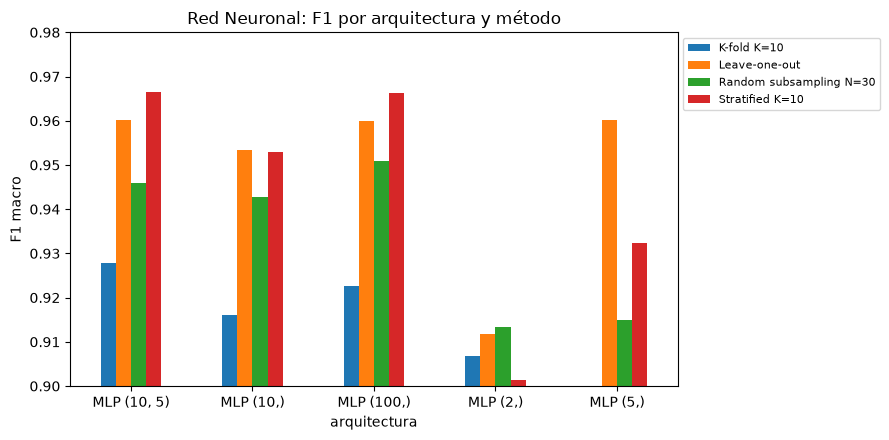

In [28]:
arquitecturas = [(2,), (5,), (10,), (10, 5), (100,)]
filas_arq = []

for arq in arquitecturas:
    nombre_arq = f"MLP {arq}"
    for metodo, parts in particiones.items():
        lista, reales, preds = [], [], []
        for tr, te in parts:
            modelo = make_pipeline(StandardScaler(),
                                   MLPClassifier(hidden_layer_sizes=arq, max_iter=1000,
                                                 random_state=semilla_modelos))
            modelo.fit(X.iloc[tr], y_arr[tr])
            p = modelo.predict(X.iloc[te])
            reales.append(y_arr[te]); preds.append(p)
            if metodo != "Leave-one-out":
                lista.append(metricas(y_arr[te], p))
        reales, preds = np.concatenate(reales), np.concatenate(preds)
        fila = {"arquitectura": nombre_arq, "método": metodo}
        if metodo == "Leave-one-out":
            for kk, v in metricas(reales, preds).items():
                fila[kk] = v; fila[kk + "_std"] = np.nan
        else:
            dfm = pd.DataFrame(lista)
            for kk in dfm.columns:
                fila[kk] = dfm[kk].mean()
                fila[kk + "_std"] = dfm[kk].std(ddof=1) if len(dfm) > 1 else np.nan
        filas_arq.append(fila)
    print("listo:", nombre_arq)

barrido = pd.DataFrame(filas_arq)

# 1) Ranking por F1 medio en los 4 métodos de validación cruzada
cv_arq = barrido[barrido["método"].isin(metodos_cv)]
rank_arq = (cv_arq.groupby("arquitectura")
                  .agg(F1_medio=("F1", "mean"),
                       exactitud_media=("exactitud", "mean"),
                       F1_std_medio=("F1_std", "mean"))
                  .reset_index()
                  .sort_values("F1_medio", ascending=False)
                  .reset_index(drop=True))
rank_arq["dif_vs_mejor"] = rank_arq["F1_medio"] - rank_arq["F1_medio"].iloc[0]
rank_arq["empate_tecnico"] = rank_arq["dif_vs_mejor"].abs() < 0.0067
print("\n=== Ranking de arquitecturas (sin FS) ===")
print(rank_arq.round(4).to_string())

# 2) Señal de memorización: exactitud en 100/100
print("\n=== Exactitud en 100/100 (memorización) ===")
print(barrido[barrido["método"] == "Train/Test 100/100"][["arquitectura", "exactitud"]].round(4).to_string(index=False))

# 3) Gráfica (fondo blanco)
pivote_arq = cv_arq.pivot_table(index="arquitectura", columns="método", values="F1")
fig, ax = plt.subplots(figsize=(9, 4.5), facecolor="white")
ax.set_facecolor("white")
pivote_arq.plot(kind="bar", ax=ax)
ax.set_ylim(0.90, 0.98)
ax.set_ylabel("F1 macro")
ax.set_title("Red Neuronal: F1 por arquitectura y método")
ax.tick_params(axis="x", rotation=0)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [29]:
resultados_5 = []
for s in [1, 2, 3, 4, 5]:
    accs = []
    for tr, te in particiones["Stratified K=10"]:
        m = make_pipeline(StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=(5,), max_iter=1000, random_state=s))
        m.fit(X.iloc[tr], y_arr[tr])
        accs.append(accuracy_score(y_arr[te], m.predict(X.iloc[te])))
    resultados_5.append({"semilla": s, "exactitud_media": np.mean(accs)})
print(pd.DataFrame(resultados_5).round(4))

C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_netwo

   semilla  exactitud_media
0        1           0.9600
1        2           0.9533
2        3           0.9533
3        4           0.9533
4        5           0.9733


C:\Users\manue\miniconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [30]:
try:
    todo_iris = pd.concat([resumen_sin_fs.assign(fs="Sin FS"),
                           resumen_fs.assign(fs="Con FS (ANOVA k=2)")], ignore_index=True)
except NameError:
    raise SystemExit("resumen_sin_fs / resumen_fs no están en memoria: hay que volver a correr el Bloque 2 y 3 de Iris.")

metodos_iris = ["Random subsampling N=30", "K-fold K=10", "Leave-one-out", "Stratified K=10"]
cv = todo_iris[todo_iris["método"].isin(metodos_iris)]
t = (cv.groupby(["modelo", "fs"])
       .agg(F1=("F1", "mean"), F1_std=("F1_std", "mean"),
            exactitud=("exactitud", "mean"), recall=("recall", "mean"),
            precision=("precision", "mean"), MCC=("MCC", "mean"))
       .reset_index())

full = todo_iris[todo_iris["método"] == "Train/Test 100/100"].set_index(["modelo", "fs"])["exactitud"]
t["brecha_overfitting"] = [full[(m, f)] - e for m, f, e in zip(t["modelo"], t["fs"], t["exactitud"])]

t = t.sort_values("F1", ascending=False).reset_index(drop=True)
t.insert(0, "puesto", t.index + 1)
t.round(4).to_csv("tabla_maestra_iris.csv", index=False)
print(t.round(4).to_string(index=False))

 puesto              modelo                 fs     F1  F1_std  exactitud  recall  precision    MCC  brecha_overfitting
      1                 SVM             Sin FS 0.9544  0.0555     0.9622  0.9565     0.9576 0.9450              0.0111
      2         Naive Bayes Con FS (ANOVA k=2) 0.9515  0.0589     0.9593  0.9531     0.9540 0.9400              0.0007
      3        Red Neuronal             Sin FS 0.9500  0.0665     0.9578  0.9521     0.9529 0.9382              0.0156
      4                 SVM Con FS (ANOVA k=2) 0.9479  0.0563     0.9557  0.9500     0.9514 0.9354              0.0043
      5 Regresión Logística Con FS (ANOVA k=2) 0.9459  0.0588     0.9538  0.9480     0.9492 0.9323             -0.0004
      6        Red Neuronal Con FS (ANOVA k=2) 0.9459  0.0589     0.9538  0.9480     0.9493 0.9324              0.0062
      7   Árbol de Decisión Con FS (ANOVA k=2) 0.9457  0.0473     0.9460  0.9479     0.9517 0.9225              0.0474
      8 Regresión Logística             Sin FS 0